# DATA-511: Homework Assignment 7

## Instructions

- This homework assignment is worth **59** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: November 6, 2026, by 11:59 PM.**

# Exercise 1 (3 points)

What does the Central Limit Theorem support in simulation results?

- (a) Independence of variables
- (b) Linear regression validity
- (c) Normality of sampling distribution
- (d) Convergence of time series
- (e) All of the above

c

# Exercise 2 (4 points)

What does convergence in a simulation indicate?

The estimate stabilizes near its long-run value as the number of iterations increases.

# Exercise 3 (5 points)

Simulate 10,000 rolls of a fair 6-sided die and plot the frequency of each outcome.

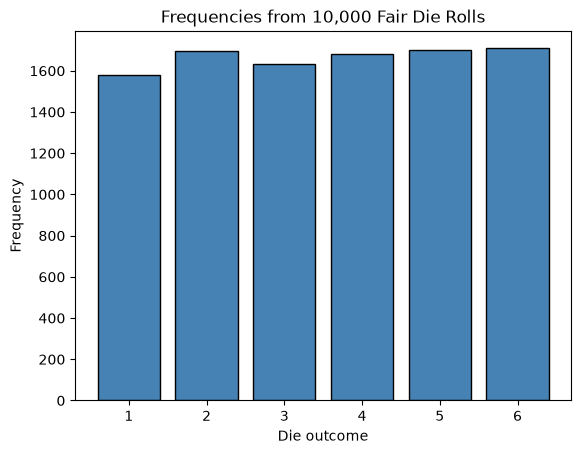

{np.int64(1): np.int64(1577), np.int64(2): np.int64(1696), np.int64(3): np.int64(1634), np.int64(4): np.int64(1683), np.int64(5): np.int64(1702), np.int64(6): np.int64(1708)}


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(511)
rolls = rng.integers(1, 7, size=10_000)
outcomes = np.arange(1, 7)
frequencies = np.bincount(rolls, minlength=7)[1:]

plt.bar(outcomes, frequencies, color="steelblue", edgecolor="black")
plt.xticks(outcomes)
plt.xlabel("Die outcome")
plt.ylabel("Frequency")
plt.title("Frequencies from 10,000 Fair Die Rolls")
plt.show()
print(dict(zip(outcomes, frequencies)))

# Exercise 4 (4 points)

What is the key limitation of changing multiple coefficients in a simulation at once?

Changing several coefficients at once makes it hard to tell which change caused the result.

# Exercise 5 (3 points)

What does the burn-in period refer to in simulations?

- (a) The time it takes to prepare the script
- (b) The warm-up iterations before steady-state is reached
- (c) The errors at the end of simulation
- (d) A failed simulation
- (e) None of the above

b

# Exercise 6 (7 points)

Create a trace plot showing convergence of mean die rolls over 5000 iterations.

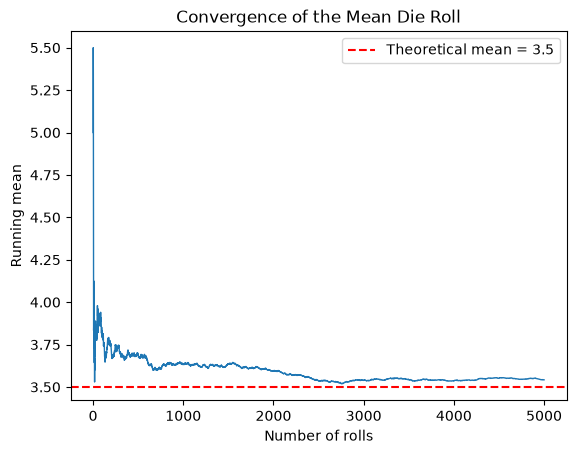

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(511)
rolls = rng.integers(1, 7, size=5_000)
running_mean = np.cumsum(rolls) / np.arange(1, len(rolls) + 1)

plt.plot(np.arange(1, len(rolls) + 1), running_mean, linewidth=1)
plt.axhline(3.5, color="red", linestyle="--", label="Theoretical mean = 3.5")
plt.xlabel("Number of rolls")
plt.ylabel("Running mean")
plt.title("Convergence of the Mean Die Roll")
plt.legend()
plt.show()

# Exercise 7 (3 points)

In simulation, what kind of variables does the triangular distribution model best?

- (a) Bounded continuous variables with known extremes and mode
- (b) Binary
- (c) Discrete uniform
- (d) Time-based events
- (e) All of the above

b

# Exercise 8 (7 points)

Simulate 1000 iterations of annualized return over 10 years assuming yearly returns follow a normal distribution with 7% mean and 15% standard deviation. Visualize the returns with a histogram.

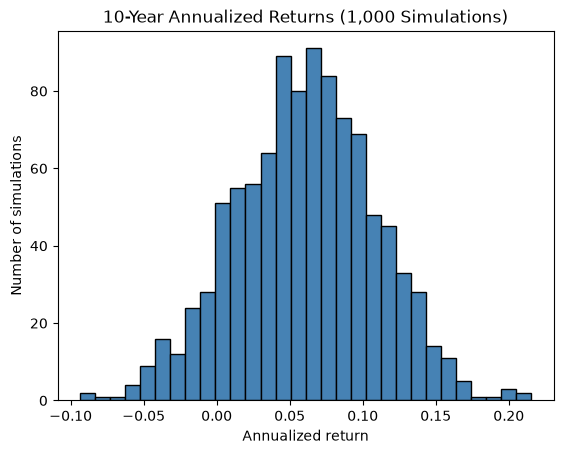

Mean annualized return: 6.08%


In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(511)
yearly_returns = rng.normal(loc=0.07, scale=0.15, size=(1_000, 10))
# Convert each 10-year path to its compound annual growth rate.
annualized_returns = np.prod(1 + yearly_returns, axis=1) ** (1 / 10) - 1

plt.hist(annualized_returns, bins=30, color="steelblue", edgecolor="black")
plt.xlabel("Annualized return")
plt.ylabel("Number of simulations")
plt.title("10-Year Annualized Returns (1,000 Simulations)")
plt.show()
print(f"Mean annualized return: {annualized_returns.mean():.2%}")

# Exercise 9 (8 points)

Perform bootstrapping to estimate the standard error of a linear regression coefficient. Consider the below code snippet:

```
import pandas as pd

# Generate sample data
np.random.seed(1)
x = np.random.rand(100)
y = 2 * x + np.random.normal(0, 0.1, 100)
df = pd.DataFrame({'x': x, 'y': y})

```

Take 1,000 bootstrap samples from `df`. For each bootstrap sample, estimate the slope of the line and store the values in a list. Visualize the estimated slopes using a histogram and report the standard deviation of these estimated slopes.

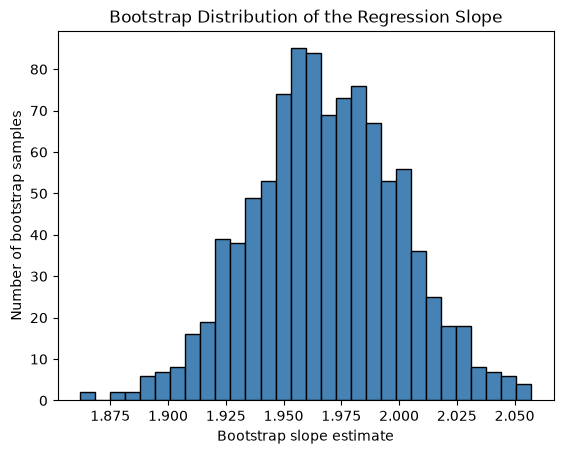

Bootstrap standard error of slope: 0.0319


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Generate sample data
np.random.seed(1)
x = np.random.rand(100)
y = 2 * x + np.random.normal(0, 0.1, 100)
df = pd.DataFrame({"x": x, "y": y})

bootstrap_slopes = []
for _ in range(1_000):
    sample = df.sample(n=len(df), replace=True)
    slope = np.polyfit(sample["x"], sample["y"], 1)[0]
    bootstrap_slopes.append(slope)

bootstrap_se = np.std(bootstrap_slopes, ddof=1)
plt.hist(bootstrap_slopes, bins=30, color="steelblue", edgecolor="black")
plt.xlabel("Bootstrap slope estimate")
plt.ylabel("Number of bootstrap samples")
plt.title("Bootstrap Distribution of the Regression Slope")
plt.show()
print(f"Bootstrap standard error of slope: {bootstrap_se:.4f}")

# Exercise 10 (3 points)

An analyst re-runs a pricing model at prices of \$5, \$6, and \$7 while keeping the estimated price elasticity fixed, and compares the resulting revenue across the three options. Which type of analysis is this?

- (a) Sensitivity analysis
- (b) What-if analysis
- (c) Bootstrapping
- (d) Burn-in analysis
- (e) None of the above

b

# Exercise 11 (4 points)

A manager compares two pricing options and says: "Option A has a higher profit margin than Option B, so Option A is better." Explain why this conclusion may be wrong, and describe how you would decide which option to recommend.

Margin alone does not show total profit...a lower-margin option may sell more or cost less. Compare expected total profit and consider demand and cost uncertainty before recommending.

# Exercise 12 (8 points)

A subscription service models the probability that a customer subscribes at price $P$ with a logit take-rate model:

$$Z = \beta_0 + \beta_1 P, \qquad \text{take} = \frac{e^Z}{1 + e^Z},$$

with $\beta_0 = 3.65529739$ and $\beta_1 = -0.559989$. The market size is 10,000,000 potential customers and the acquisition cost is \$1.50 per subscriber. Contribution is `subscribers * (price - acquisition cost)`.

- (a) **What-if analysis (4 points):** For prices from \$3.00 to \$10.00 in steps of \$0.25 (parameters held fixed), compute the contribution at each price. Plot contribution against price and report the price that maximizes contribution.
- (b) **Sensitivity analysis (4 points):** Now suppose $\beta_1$ is uncertain, with $\hat\beta_1 \sim N(-0.559989,\ 0.05^2)$. Draw 1,000 values of $\beta_1$ (use `np.random.default_rng(511)`). For each draw, find the contribution-maximizing price on the same grid. Visualize the 1,000 optimal prices with a histogram and report their mean and standard deviation. Is the recommendation from (a) robust to estimation error?

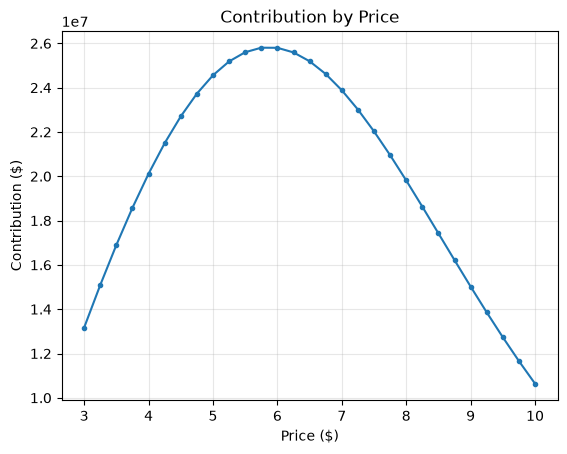

Contribution-maximizing price: $5.75
Maximum contribution: $25,804,002.95


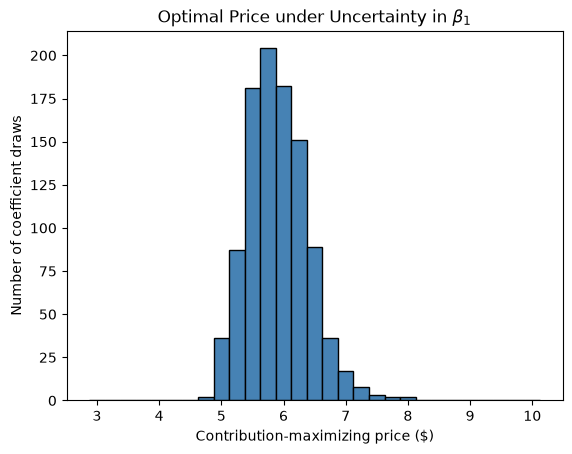

Mean optimal price: $5.90
Standard deviation: $0.49
The recommendation is fairly robust: the mean optimal price ($5.90) is close to the what-if optimum ($5.75), with a standard deviation of $0.49.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

beta_0 = 3.65529739
beta_1 = -0.559989
market_size = 10_000_000
acquisition_cost = 1.50
prices = np.arange(3.00, 10.00 + 0.25, 0.25)

def contribution(price, slope):
    z = beta_0 + slope * price
    take_rate = 1 / (1 + np.exp(-z))
    subscribers = market_size * take_rate
    return subscribers * (price - acquisition_cost)

# (a) What-if analysis with the estimated coefficients held fixed.
contributions = contribution(prices, beta_1)
best_index = np.argmax(contributions)
best_price = prices[best_index]
plt.plot(prices, contributions, marker="o", markersize=3)
plt.xlabel("Price ($)")
plt.ylabel("Contribution ($)")
plt.title("Contribution by Price")
plt.grid(True, alpha=0.3)
plt.show()
print(f"Contribution-maximizing price: ${best_price:.2f}")
print(f"Maximum contribution: ${contributions[best_index]:,.2f}")

# (b) Sensitivity analysis over uncertainty in the estimated price coefficient.
rng = np.random.default_rng(511)
beta_1_draws = rng.normal(loc=-0.559989, scale=0.05, size=1_000)
draw_contributions = contribution(prices[None, :], beta_1_draws[:, None])
optimal_prices = prices[np.argmax(draw_contributions, axis=1)]

plt.hist(optimal_prices, bins=np.arange(2.875, 10.126, 0.25),
         color="steelblue", edgecolor="black", align="mid")
plt.xlabel("Contribution-maximizing price ($)")
plt.ylabel("Number of coefficient draws")
plt.title("Optimal Price under Uncertainty in $\\beta_1$")
plt.xticks(prices[::4])
plt.show()
print(f"Mean optimal price: ${optimal_prices.mean():.2f}")
print(f"Standard deviation: ${optimal_prices.std(ddof=1):.2f}")
print(f"The recommendation is fairly robust: the mean optimal price (${optimal_prices.mean():.2f}) is close to the what-if optimum (${best_price:.2f}), with a standard deviation of ${optimal_prices.std(ddof=1):.2f}.")